# Phân tích lưu lượng NHPP từ dữ liệu thực nghiệm

Notebook này chỉ **đọc** mã nguồn và dữ liệu trong **dataset/raw/nhpp**; không sinh dữ liệu thay thế và không ghi đè dữ liệu gốc.

Mục tiêu:

1. đối chiếu cường độ phiên lý thuyết với phiên trong **arrival_trace.csv**;
2. tách biệt RPS thiết kế, request được Locust ghi nhận và request được Jaeger quan sát;
3. kiểm tra phân phối Poisson khi cường độ thay đổi;
4. căn chỉnh pha trước khi so sánh nhiều run;
5. lập bảng chỉ số và sinh kết luận dựa trên dữ liệu.

> Phụ thuộc: Python, Pandas, NumPy, Matplotlib và SciPy. Nếu còn thiếu: `python -m pip install pandas numpy matplotlib scipy`.

In [24]:
from pathlib import Path
import importlib.util
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

try:
    from scipy.integrate import quad
    from scipy.stats import norm, poisson
except ImportError as exc:
    raise ImportError(
        "Notebook cần SciPy. Cài bằng: python -m pip install scipy"
    ) from exc

plt.rcParams.update({
    "figure.dpi": 115,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 100)

# ======================== CẤU HÌNH NGƯỜI DÙNG ========================
WINDOW_SEC = 10                 # Chỉ nhận 1, 5 hoặc 10 giây
RUN_SELECTION = None            # None = tất cả; ví dụ ["run_01", "run_03"]
DETAIL_RUN = None               # None = run đầu tiên trong RUN_SELECTION
STABLE_REL_TOL = 0.05           # Dải ổn định quanh base: ±5%
# ====================================================================

if WINDOW_SEC not in {1, 5, 10}:
    raise ValueError("WINDOW_SEC phải là 1, 5 hoặc 10 giây")

def locate_project_root(start: Path) -> Path:
    for p in [start.resolve(), *start.resolve().parents]:
        if (p / "dataset" / "raw").is_dir():
            return p
    raise FileNotFoundError(
        "Không tìm thấy dataset/raw từ thư mục làm việc hiện tại."
    )

PROJECT_ROOT = locate_project_root(Path.cwd())
RESULTS_DIR = PROJECT_ROOT / "dataset" / "raw" / "nhpp"
SCENARIO_FILE = PROJECT_ROOT / "load-testing" / "scenarios" / "nhpp.py"

print("Project root :", PROJECT_ROOT)
print("NHPP results :", RESULTS_DIR)
print("Window       :", WINDOW_SEC, "giây")

Project root : F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling
NHPP results : F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling\math-load-testing\results\nhpp
Window       : 10 giây


## 1. Công thức và tham số đọc trực tiếp từ mã nguồn

Mã triển khai cường độ **phiên**, không phải cường độ HTTP request:

$$
\lambda(t)=\max\left(
0.5,\;
7+5\sin\left(\frac{2\pi t}{900}+\varphi\right)
+1.5\sin\left(\frac{4\pi t}{900}+2\varphi\right)
\right).
$$

- $t$: số giây kể từ lúc driver bắt đầu phát trace;
- $\lambda(t)$: phiên/giây;
- $\varphi$: pha lấy một lần cho mỗi run và lưu trong **trace_meta.json**;
- mỗi phiên gồm một request trang chủ và $K\sim\mathrm{Geometric}(E[K]=5)$ thao tác, nên mã đặt RPS thiết kế bằng $6\lambda(t)$.

Nguồn: **scenarios/nhpp.py**, **arrival_models.py**, **locustfile.py**.

In [25]:
spec = importlib.util.spec_from_file_location("nhpp_scenario_config", SCENARIO_FILE)
nhpp_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(nhpp_module)
CFG = dict(nhpp_module.CONFIG)

BASE = float(CFG["base"])
AMP1 = float(CFG["amp1"])
AMP2 = float(CFG["amp2"])
FLOOR = float(CFG["floor"])
PERIOD = float(CFG["period_sec"])
REQUESTS_PER_SESSION = 1.0 + float(CFG["mean_actions"])
OMEGA = 2.0 * np.pi / PERIOD

param_table = pd.DataFrame([
    ("base", BASE, "phiên/giây", "mức nền"),
    ("amp1", AMP1, "phiên/giây", "biên độ điều hòa cơ bản"),
    ("amp2", AMP2, "phiên/giây", "biên độ điều hòa bậc hai"),
    ("floor", FLOOR, "phiên/giây", "cận dưới"),
    ("period_sec", PERIOD, "giây", "chu kỳ tổng hợp"),
    ("mean_actions", CFG["mean_actions"], "action/phiên", "E[K]"),
    ("think_mean_sec", CFG["think_mean_sec"], "giây", "thời gian nghỉ trung bình"),
], columns=["tham_số", "giá_trị", "đơn_vị", "ý_nghĩa"])
display(param_table)
print(f"RPS thiết kế = {REQUESTS_PER_SESSION:g} × lambda(t)")

,tham_số,giá_trị,đơn_vị,ý_nghĩa
0,base,7.0,phiên/giây,mức nền
1,amp1,5.0,phiên/giây,biên độ điều hòa cơ bản
2,amp2,1.5,phiên/giây,biên độ điều hòa bậc hai
3,floor,0.5,phiên/giây,cận dưới
4,period_sec,900.0,giây,chu kỳ tổng hợp
5,mean_actions,5.0,action/phiên,E[K]
6,think_mean_sec,2.0,giây,thời gian nghỉ trung bình


RPS thiết kế = 6 × lambda(t)


## 2. Khảo sát dữ liệu và đồng bộ thời gian

Notebook tự tìm mọi thư mục con có **arrival_trace.csv**.

| Tệp | Đơn vị/mốc thời gian | Nội dung sử dụng |
|---|---|---|
| arrival_trace.csv | t tương đối, giây từ đầu trace | thời điểm bắt đầu phiên; size = số action |
| trace_meta.json | tương đối | pha thật, duration, số event |
| designed_rate.csv | t tương đối, lưới 1 giây | bản ghi kiểm tra lambda và RPS thiết kế |
| locust_stats_history.csv | Unix epoch, giây | request hoàn tất/được Locust ghi nhận tích lũy |
| locust_stats.csv | toàn run | tổng request và failure phía client |
| service_metrics.csv | Unix epoch, thường 10 giây | span server Jaeger tại frontend |
| driver_report.json | toàn run | planned/started/dropped/completed/failed session |
| meta.json | Unix epoch | start/end, duration, bước telemetry |

**arrival_trace.t=0** không có Unix timestamp riêng. Notebook dùng timestamp đầu tiên trong Locust history có **User Count > 0** làm mốc thực thi gần nhất. Jaeger luôn được giữ ở độ phân giải gốc; không chia giả cửa sổ 10 giây thành 1 hoặc 5 giây.

In [26]:
def read_json(path: Path):
    if not path.exists():
        return {}
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)

def read_csv_optional(path: Path):
    if not path.exists():
        return pd.DataFrame()
    try:
        return pd.read_csv(path)
    except Exception as exc:
        warnings.warn(f"Không đọc được {path}: {exc}")
        return pd.DataFrame()

def load_run(run_dir: Path):
    meta = read_json(run_dir / "meta.json")
    trace_meta = read_json(run_dir / "trace_meta.json")
    driver = read_json(run_dir / "driver_report.json")
    collect = read_json(run_dir / "collect_report.json")
    arrival = read_csv_optional(run_dir / "arrival_trace.csv")
    designed = read_csv_optional(run_dir / "designed_rate.csv")
    locust_hist = read_csv_optional(run_dir / "locust_stats_history.csv")
    locust_stats = read_csv_optional(run_dir / "locust_stats.csv")
    service = read_csv_optional(run_dir / "service_metrics.csv")

    duration = int(trace_meta.get("duration", meta.get("duration_sec", 0)) or 0)
    phase = trace_meta.get("meta", {}).get("phase", np.nan)
    issues = []
    if not {"t", "kind", "source", "size"}.issubset(arrival.columns):
        issues.append("arrival_trace thiếu cột bắt buộc")
    if not np.isfinite(phase):
        issues.append("không có phase trong trace_meta.json")
    if duration <= 0:
        issues.append("duration không hợp lệ")
    if meta.get("run_id") and meta.get("run_id") != run_dir.name:
        issues.append(f"folder={run_dir.name} nhưng meta.run_id={meta.get('run_id')}")

    driver_epoch = np.nan
    if not locust_hist.empty and {"Timestamp", "Name"}.issubset(locust_hist.columns):
        h = locust_hist.loc[locust_hist["Name"].eq("Aggregated")].copy()
        if not h.empty:
            users = pd.to_numeric(h.get("User Count"), errors="coerce")
            active = h.loc[users.gt(0)]
            driver_epoch = float((active if not active.empty else h)["Timestamp"].iloc[0])
    if not np.isfinite(driver_epoch) and meta.get("start") is not None:
        driver_epoch = float(meta["start"])
        issues.append("mốc driver fallback về meta.start")

    return {
        "key": run_dir.name,
        "dir": run_dir,
        "meta": meta,
        "trace_meta": trace_meta,
        "driver": driver,
        "collect": collect,
        "arrival": arrival,
        "designed": designed,
        "locust_hist": locust_hist,
        "locust_stats": locust_stats,
        "service": service,
        "duration": duration,
        "phase": float(phase),
        "driver_epoch": driver_epoch,
        "issues": issues,
    }

run_dirs = sorted(
    [p for p in RESULTS_DIR.iterdir() if p.is_dir() and (p / "arrival_trace.csv").exists()],
    key=lambda p: p.name,
)
if not run_dirs:
    raise FileNotFoundError(f"Không tìm thấy run NHPP trong {RESULTS_DIR}")

ALL_RUNS = {d.name: load_run(d) for d in run_dirs}
if RUN_SELECTION is None:
    selected_keys = list(ALL_RUNS)
else:
    missing = sorted(set(RUN_SELECTION) - set(ALL_RUNS))
    if missing:
        raise KeyError(f"Không tìm thấy các run: {missing}")
    selected_keys = list(RUN_SELECTION)

RUNS = {k: ALL_RUNS[k] for k in selected_keys}
DETAIL_RUN = DETAIL_RUN or selected_keys[0]
if DETAIL_RUN not in RUNS:
    raise KeyError(f"DETAIL_RUN={DETAIL_RUN!r} không thuộc tập run đã chọn")

print(f"Tìm thấy {len(ALL_RUNS)} run; đang phân tích {len(RUNS)} run:", ", ".join(RUNS))

Tìm thấy 8 run; đang phân tích 8 run: run_01, run_02, run_03, run_04, run_05, run_06, run_07, run_08


In [27]:
inventory_rows = []
for key, r in ALL_RUNS.items():
    a = r["arrival"]
    sessions = a.loc[a["kind"].eq("session")] if "kind" in a else pd.DataFrame()
    inventory_rows.append({
        "folder": key,
        "meta_run_id": r["meta"].get("run_id"),
        "seed": r["meta"].get("seed"),
        "duration_s": r["duration"],
        "phase_rad": r["phase"],
        "session_rows": len(sessions),
        "meta_start_epoch": r["meta"].get("start"),
        "driver_epoch_used": r["driver_epoch"],
        "telemetry_step_s": r["meta"].get("step_sec"),
        "file_count": len(list(r["dir"].glob("*"))),
        "issues": "; ".join(r["issues"]) or "OK",
    })

inventory = pd.DataFrame(inventory_rows).set_index("folder")
display(inventory.style.format({"phase_rad": "{:.6f}", "driver_epoch_used": "{:.0f}"}))

issue_count = inventory["issues"].ne("OK").sum()
if issue_count:
    display(Markdown(
        f"> **Cảnh báo metadata:** {issue_count} thư mục có ghi chú. "
        "Notebook dùng tên thư mục làm khóa và giữ meta_run_id riêng; không tự sửa dữ liệu."
    ))

,meta_run_id,seed,duration_s,phase_rad,session_rows,meta_start_epoch,driver_epoch_used,telemetry_step_s,file_count,issues
folder,,,,,,,,,,
run_01,run_02,1002,1800,3.273215,12641,1791358985,1791358987,10,14,folder=run_01 nhưng meta.run_id=run_02
run_02,run_03,1003,1800,3.124888,12555,1791361442,1791361444,10,14,folder=run_02 nhưng meta.run_id=run_03
run_03,run_04,1004,1800,2.646006,12702,1791363912,1791363914,10,14,folder=run_03 nhưng meta.run_id=run_04
run_04,run_05,1005,1800,3.035472,12534,1791366513,1791366515,10,14,folder=run_04 nhưng meta.run_id=run_05
run_05,run_06,1006,1800,2.177877,12674,1791369008,1791369010,10,14,folder=run_05 nhưng meta.run_id=run_06
run_06,run_07,1007,1800,5.378026,12620,1791371636,1791371638,10,14,folder=run_06 nhưng meta.run_id=run_07
run_07,run_08,1008,1800,3.266149,12379,1791373813,1791373815,10,14,folder=run_07 nhưng meta.run_id=run_08
run_08,run_09,1009,1800,1.132182,12559,1791376402,1791376404,10,14,folder=run_08 nhưng meta.run_id=run_09


> **Cảnh báo metadata:** 8 thư mục có ghi chú. Notebook dùng tên thư mục làm khóa và giữ meta_run_id riêng; không tự sửa dữ liệu.

## 3. Tích phân kỳ vọng và tổng hợp cửa sổ

Với mỗi cửa sổ $[a,b)$:

$$
\mu_{a,b}=\int_a^b\lambda(t)\,dt,
\qquad N_{a,b}\sim\mathrm{Poisson}(\mu_{a,b}).
$$

Notebook dùng **scipy.integrate.quad** để tích phân cả phép lấy cận dưới. RPS thiết kế trung bình trong cửa sổ là $6\mu_{a,b}/(b-a)$.

In [28]:
def lambda_sessions(t, phase):
    t = np.asarray(t, dtype=float)
    raw = (
        BASE
        + AMP1 * np.sin(OMEGA * t + phase)
        + AMP2 * np.sin(2 * OMEGA * t + 2 * phase)
    )
    return np.maximum(FLOOR, raw)

def expected_sessions(a, b, phase):
    value, _ = quad(
        lambda x: float(lambda_sessions(x, phase)),
        float(a), float(b),
        epsabs=1e-9, epsrel=1e-9, limit=100,
    )
    return value

def locust_window_counts(run, edges):
    h = run["locust_hist"]
    needed = {"Timestamp", "Name", "Total Request Count"}
    if h.empty or not needed.issubset(h.columns) or not np.isfinite(run["driver_epoch"]):
        return np.full(len(edges) - 1, np.nan)

    h = h.loc[h["Name"].eq("Aggregated")].copy()
    h["Timestamp"] = pd.to_numeric(h["Timestamp"], errors="coerce")
    h["cum"] = pd.to_numeric(h["Total Request Count"], errors="coerce")
    h = h.dropna(subset=["Timestamp", "cum"]).sort_values("Timestamp")
    h = h.groupby("Timestamp", as_index=False)["cum"].max()
    if h.empty:
        return np.full(len(edges) - 1, np.nan)

    h["count"] = h["cum"].diff().fillna(h["cum"]).clip(lower=0)
    h["t"] = h["Timestamp"] - run["driver_epoch"]
    valid = h["t"].between(edges[0], edges[-1], inclusive="left")
    return np.histogram(
        h.loc[valid, "t"], bins=edges, weights=h.loc[valid, "count"]
    )[0]

def jaeger_frontend_series(run):
    s = run["service"]
    needed = {"timestamp", "service", "request_count"}
    if s.empty or not needed.issubset(s.columns) or not np.isfinite(run["driver_epoch"]):
        return pd.DataFrame(columns=["t", "rps"])

    x = s.loc[s["service"].eq("frontend"), ["timestamp", "request_count"]].copy()
    x["timestamp"] = pd.to_numeric(x["timestamp"], errors="coerce")
    x["request_count"] = pd.to_numeric(x["request_count"], errors="coerce")
    x = x.dropna()
    native_step = float(run["meta"].get("step_sec", run["collect"].get("step", 10)) or 10)
    x["t"] = x["timestamp"] - run["driver_epoch"] + native_step / 2
    x["rps"] = x["request_count"] / native_step
    return x.loc[x["t"].between(0, run["duration"]), ["t", "rps"]].sort_values("t")

def analyze_run(run, window):
    duration = run["duration"]
    edges = np.arange(0.0, duration + window, window, dtype=float)
    if edges[-1] > duration:
        edges[-1] = duration
    edges = np.unique(edges)
    a, b = edges[:-1], edges[1:]
    widths = b - a
    mu = np.array([expected_sessions(x, y, run["phase"]) for x, y in zip(a, b)])

    trace = run["arrival"]
    if {"t", "kind"}.issubset(trace.columns):
        times = pd.to_numeric(
            trace.loc[trace["kind"].eq("session"), "t"], errors="coerce"
        ).dropna()
        observed = np.histogram(times, bins=edges)[0]
    else:
        observed = np.full(len(a), np.nan)

    client_count = locust_window_counts(run, edges)
    return pd.DataFrame({
        "t_start": a,
        "t_end": b,
        "t_mid": (a + b) / 2,
        "width": widths,
        "expected_sessions": mu,
        "observed_sessions": observed,
        "lambda_mean": mu / widths,
        "observed_session_rate": observed / widths,
        "designed_rps": REQUESTS_PER_SESSION * mu / widths,
        "locust_request_count": client_count,
        "locust_rps": client_count / widths,
    })

ANALYSIS = {key: analyze_run(run, WINDOW_SEC) for key, run in RUNS.items()}
print("Đã tích phân và tổng hợp", sum(len(x) for x in ANALYSIS.values()), "cửa sổ.")

Đã tích phân và tổng hợp 1440 cửa sổ.


## 4. Biểu đồ 1 — Cường độ phiên lý thuyết và thực nghiệm

Đường bậc thang là số phiên quan sát trong mỗi cửa sổ chia độ rộng cửa sổ. Dao động quanh $\lambda(t)$ là hành vi mong đợi của Poisson, không tự động là sai số triển khai.

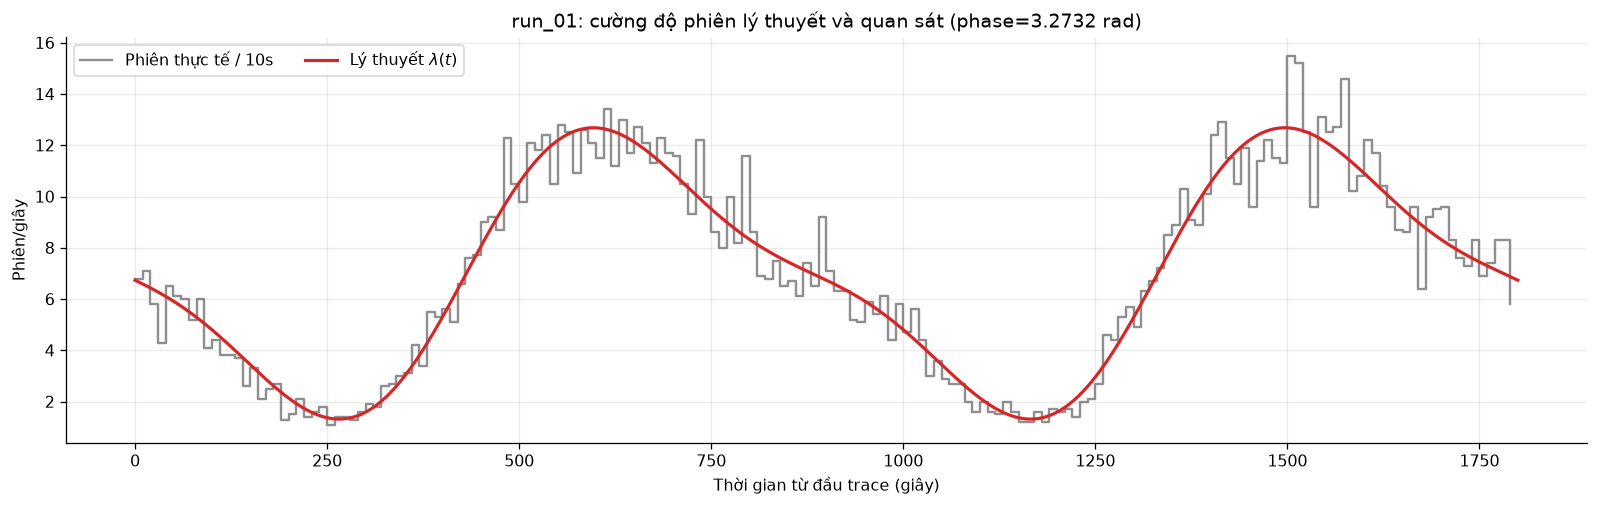

In [29]:
key = DETAIL_RUN
run, df = RUNS[key], ANALYSIS[key]
dense_t = np.linspace(0, run["duration"], max(2000, run["duration"] * 2 + 1))

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.step(
    df["t_start"], df["observed_session_rate"], where="post",
    color="0.45", alpha=0.8, label=f"Phiên thực tế / {WINDOW_SEC}s",
)
ax.plot(
    dense_t, lambda_sessions(dense_t, run["phase"]),
    color="C3", lw=2, label=r"Lý thuyết $\lambda(t)$",
)
ax.set(
    title=f"{key}: cường độ phiên lý thuyết và quan sát "
          f"(phase={run['phase']:.4f} rad)",
    xlabel="Thời gian từ đầu trace (giây)",
    ylabel="Phiên/giây",
)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 5. Biểu đồ 2 — RPS thiết kế và RPS thực tế

- **Thiết kế:** $6\lambda(t)$, tức số request kỳ vọng gắn với các phiên bắt đầu tại thời điểm đó.
- **Locust:** số request hoàn tất/được ghi nhận tại client, suy ra từ sai phân bộ đếm tích lũy. Dữ liệu không lưu timestamp phát của từng HTTP request, nên không thể dựng chính xác chuỗi “request đã phát đi”.
- **Jaeger frontend:** số span server hệ thống ghi nhận ở độ phân giải telemetry gốc. Đây có thể là mẫu con của request thực và không được tự động phóng đại để trùng Locust.

Notebook **không** dùng tổng $(1+size)$ của các phiên bắt đầu trong một giây làm RPS thực tế.

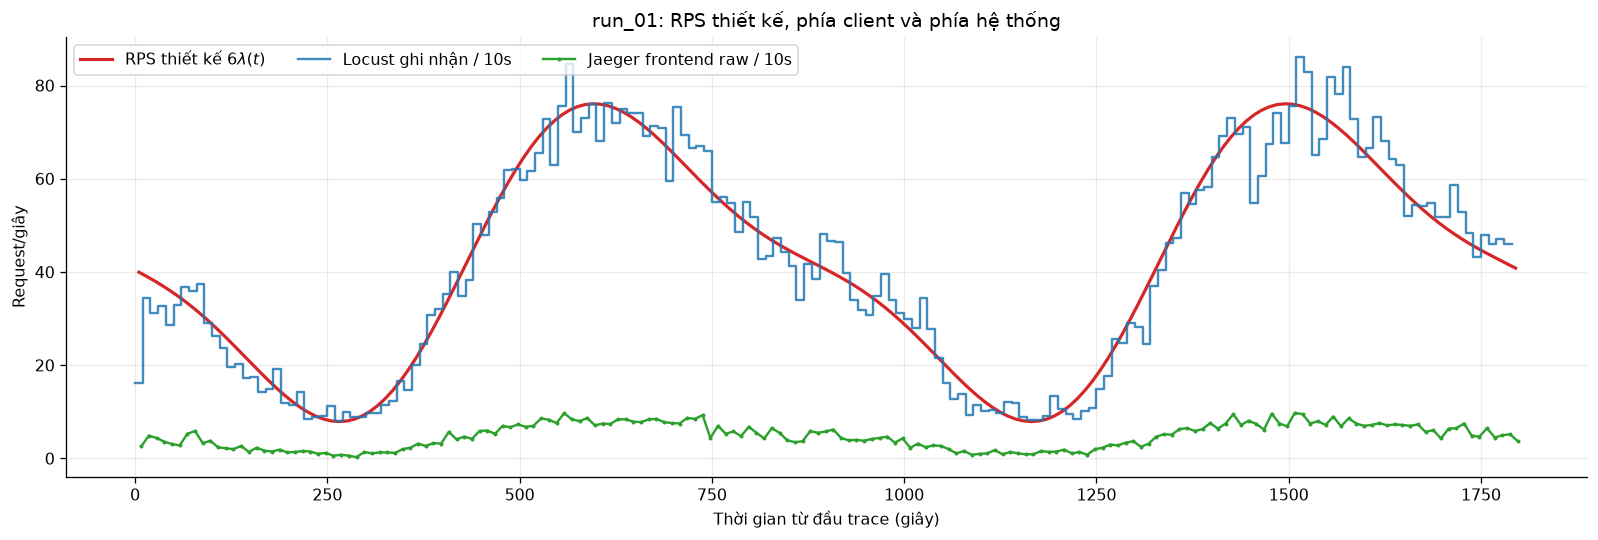

In [30]:
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(
    df["t_mid"], df["designed_rps"],
    color="C3", lw=2, label=r"RPS thiết kế $6\lambda(t)$",
)

if df["locust_rps"].notna().any():
    ax.step(
        df["t_start"], df["locust_rps"], where="post",
        color="C0", alpha=0.85, label=f"Locust ghi nhận / {WINDOW_SEC}s",
    )
else:
    warnings.warn(f"{key}: không có Locust history để tính RPS phía client")

jaeger = jaeger_frontend_series(run)
if not jaeger.empty:
    native_step = int(run["meta"].get("step_sec", 10) or 10)
    ax.plot(
        jaeger["t"], jaeger["rps"], color="C2", lw=1.5,
        marker=".", ms=3, label=f"Jaeger frontend raw / {native_step}s",
    )
else:
    warnings.warn(f"{key}: không có service_metrics của frontend")

ax.set(
    title=f"{key}: RPS thiết kế, phía client và phía hệ thống",
    xlabel="Thời gian từ đầu trace (giây)",
    ylabel="Request/giây",
)
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 6. Biểu đồ 3 — Phân phối số phiên trong vùng cường độ ổn định

Chọn cửa sổ có cường độ trung bình nằm trong ±**STABLE_REL_TOL** quanh **base**. Vì $\mu_i$ vẫn hơi khác nhau, đường lý thuyết là hỗn hợp Poisson theo đúng từng cửa sổ:

$$
P(N=k)=\frac{1}{m}\sum_{i=1}^{m}P(\mathrm{Poisson}(\mu_i)=k).
$$

Biểu đồ phụ dùng phần dư Pearson $(N_i-\mu_i)/\sqrt{\mu_i}$ để chuẩn hóa các kỳ vọng khác nhau. Xấp xỉ chuẩn chỉ là tham chiếu chẩn đoán khi $\mu_i$ đủ lớn.

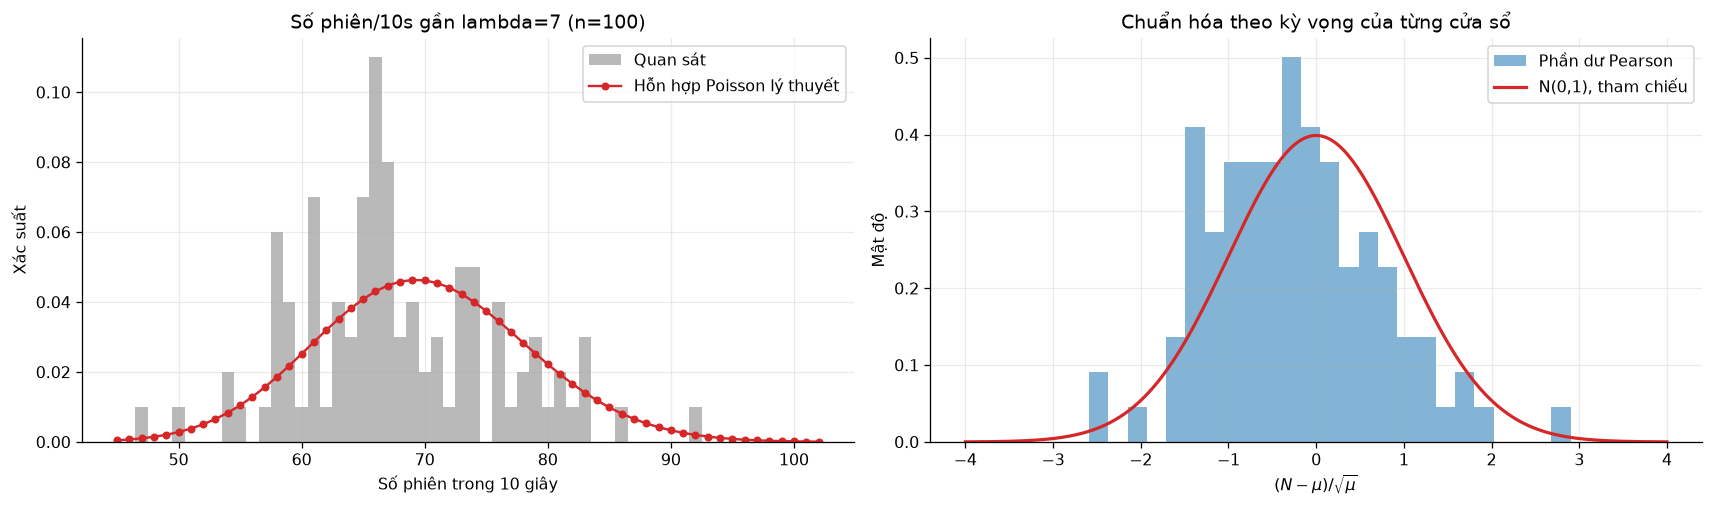

,quan_sát,tham_chiếu_lý_thuyết
mean(count),67.760000,69.846295
variance(count),66.507475,74.102438
mean(Pearson residual),-0.248919,0.000000
variance(Pearson residual),0.916768,1.000000


In [31]:
stable_parts = []
for key_i, x in ANALYSIS.items():
    mask = (x["lambda_mean"] - BASE).abs() <= STABLE_REL_TOL * BASE
    part = x.loc[mask, ["expected_sessions", "observed_sessions"]].copy()
    part["run"] = key_i
    stable_parts.append(part)

stable = pd.concat(stable_parts, ignore_index=True) if stable_parts else pd.DataFrame()
if len(stable) < 30:
    warnings.warn(
        f"Chỉ có {len(stable)} cửa sổ ổn định; "
        "hãy tăng STABLE_REL_TOL nếu cần diễn giải phân phối."
    )

obs = stable["observed_sessions"].astype(int).to_numpy()
mu = stable["expected_sessions"].to_numpy(float)
k_min = max(0, int(obs.min()) - 2)
k_max = int(max(obs.max(), poisson.ppf(0.999, mu.max()))) + 1
ks = np.arange(k_min, k_max + 1)
mixture_pmf = np.mean(poisson.pmf(ks[:, None], mu[None, :]), axis=1)
residual = (obs - mu) / np.sqrt(mu)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.arange(obs.min() - 0.5, obs.max() + 1.5, 1)
axes[0].hist(
    obs, bins=bins, density=True, alpha=0.55, color="0.5", label="Quan sát"
)
axes[0].plot(
    ks, mixture_pmf, "o-", color="C3", ms=4,
    label="Hỗn hợp Poisson lý thuyết",
)
axes[0].set(
    title=f"Số phiên/{WINDOW_SEC}s gần lambda={BASE:g} (n={len(stable)})",
    xlabel=f"Số phiên trong {WINDOW_SEC} giây",
    ylabel="Xác suất",
)
axes[0].legend()

zgrid = np.linspace(-4, 4, 300)
axes[1].hist(
    residual, bins=25, density=True, alpha=0.55,
    color="C0", label="Phần dư Pearson",
)
axes[1].plot(zgrid, norm.pdf(zgrid), color="C3", lw=2, label="N(0,1), tham chiếu")
axes[1].set(
    title="Chuẩn hóa theo kỳ vọng của từng cửa sổ",
    xlabel=r"$(N-\mu)/\sqrt{\mu}$",
    ylabel="Mật độ",
)
axes[1].legend()
plt.tight_layout()
plt.show()

mixture_mean = mu.mean()
mixture_var = mu.mean() + mu.var(ddof=0)
display(pd.DataFrame({
    "quan_sát": [obs.mean(), obs.var(ddof=1), residual.mean(), residual.var(ddof=1)],
    "tham_chiếu_lý_thuyết": [mixture_mean, mixture_var, 0.0, 1.0],
}, index=[
    "mean(count)", "variance(count)",
    "mean(Pearson residual)", "variance(Pearson residual)",
]))

## 7. Bảng chỉ số theo từng run

- MAE tính giữa số phiên quan sát và $\mu_i$ từng cửa sổ. MAE khác 0 là tất yếu với Poisson và **không** đủ để kết luận bộ sinh sai.
- **total_session_z** chuẩn hóa sai khác tổng phiên bằng $\sqrt{E[N]}$.
- Mean/variance ổn định dùng cùng dải cường độ của Biểu đồ 3; variance lý thuyết có thêm thành phần do các $\mu_i$ chưa hoàn toàn bằng nhau.
- Tổng Locust là request được client ghi nhận hoàn tất trước khi thống kê kết thúc, không phải timestamp phát request.
- **trace_assigned_work_not_actual_rps** chỉ là $\sum(1+K)$ của trace, báo cáo để kiểm tra workload nhưng không dùng làm RPS thực tế.

In [32]:
def locust_totals(run):
    x = run["locust_stats"]
    if x.empty or "Name" not in x.columns:
        return np.nan, np.nan
    agg = x.loc[x["Name"].eq("Aggregated")]
    if agg.empty:
        return np.nan, np.nan
    total = pd.to_numeric(agg["Request Count"], errors="coerce").iloc[-1]
    failed = pd.to_numeric(agg["Failure Count"], errors="coerce").iloc[-1]
    return float(total), float(failed)

def run_statistics(key, run, x):
    expected_total = x["expected_sessions"].sum()
    observed_total = x["observed_sessions"].sum()
    stable_mask = (x["lambda_mean"] - BASE).abs() <= STABLE_REL_TOL * BASE
    xs = x.loc[stable_mask]
    locust_total, locust_failed = locust_totals(run)

    trace = run["arrival"]
    if {"kind", "size"}.issubset(trace.columns):
        sess = trace.loc[trace["kind"].eq("session")]
        trace_work = (1 + pd.to_numeric(sess["size"], errors="coerce")).sum()
    else:
        trace_work = np.nan

    service = run["service"]
    if not service.empty and {"service", "request_count"}.issubset(service.columns):
        jaeger_total = pd.to_numeric(
            service.loc[service["service"].eq("frontend"), "request_count"],
            errors="coerce",
        ).sum()
    else:
        jaeger_total = np.nan

    corr = x[["lambda_mean", "observed_session_rate"]].corr().iloc[0, 1]
    stable_mu = xs["expected_sessions"].to_numpy(float)
    stable_theory_var = (
        stable_mu.mean() + stable_mu.var(ddof=0) if len(stable_mu) else np.nan
    )
    planned = float(run["driver"].get("planned", np.nan))
    dropped = float(run["driver"].get("dropped", np.nan))

    return {
        "run": key,
        "seed": run["meta"].get("seed"),
        "phase_rad": run["phase"],
        "expected_sessions": expected_total,
        "observed_sessions": observed_total,
        "total_session_z": (observed_total - expected_total) / np.sqrt(expected_total),
        "session_MAE_per_window": np.mean(
            np.abs(x["observed_sessions"] - x["expected_sessions"])
        ),
        "session_trend_corr": corr,
        "peak_session_rate": x["observed_session_rate"].max(),
        "stable_windows": int(stable_mask.sum()),
        "stable_count_mean": xs["observed_sessions"].mean(),
        "stable_count_variance": xs["observed_sessions"].var(ddof=1),
        "stable_expected_mean": xs["expected_sessions"].mean(),
        "stable_expected_variance": stable_theory_var,
        "designed_expected_requests": REQUESTS_PER_SESSION * expected_total,
        "trace_assigned_work_not_actual_rps": trace_work,
        "locust_client_requests": locust_total,
        "mean_locust_rps_over_duration": (
            locust_total / run["duration"] if np.isfinite(locust_total) else np.nan
        ),
        "peak_locust_rps_windowed": x["locust_rps"].max(),
        "locust_failures": locust_failed,
        "locust_failure_ratio": (
            locust_failed / locust_total if locust_total > 0 else np.nan
        ),
        "jaeger_frontend_spans_raw": jaeger_total,
        "jaeger_to_locust_ratio": (
            jaeger_total / locust_total if locust_total > 0 else np.nan
        ),
        "driver_dropped_sessions": dropped,
        "driver_drop_ratio": dropped / planned if planned > 0 else np.nan,
        "driver_completed_sessions": run["driver"].get("completed", np.nan),
        "driver_failed_sessions": run["driver"].get("failed", np.nan),
        "driver_max_in_flight": run["driver"].get("max_in_flight", np.nan),
        "jaeger_truncated_windows": run["collect"].get(
            "jaeger_truncated_windows", np.nan
        ),
    }

stats = pd.DataFrame([
    run_statistics(k, RUNS[k], ANALYSIS[k]) for k in RUNS
]).set_index("run")

formatters = {
    "phase_rad": "{:.5f}",
    "expected_sessions": "{:.2f}",
    "observed_sessions": "{:.0f}",
    "total_session_z": "{:.3f}",
    "session_MAE_per_window": "{:.3f}",
    "session_trend_corr": "{:.3f}",
    "peak_session_rate": "{:.2f}",
    "stable_count_mean": "{:.2f}",
    "stable_count_variance": "{:.2f}",
    "stable_expected_mean": "{:.2f}",
    "stable_expected_variance": "{:.2f}",
    "designed_expected_requests": "{:.0f}",
    "trace_assigned_work_not_actual_rps": "{:.0f}",
    "locust_client_requests": "{:.0f}",
    "mean_locust_rps_over_duration": "{:.2f}",
    "peak_locust_rps_windowed": "{:.2f}",
    "locust_failures": "{:.0f}",
    "locust_failure_ratio": "{:.4%}",
    "jaeger_frontend_spans_raw": "{:.0f}",
    "jaeger_to_locust_ratio": "{:.2%}",
    "driver_dropped_sessions": "{:.0f}",
    "driver_drop_ratio": "{:.4%}",
}
display(stats.style.format(formatters))

,seed,phase_rad,expected_sessions,observed_sessions,total_session_z,session_MAE_per_window,session_trend_corr,peak_session_rate,stable_windows,stable_count_mean,stable_count_variance,stable_expected_mean,stable_expected_variance,designed_expected_requests,trace_assigned_work_not_actual_rps,locust_client_requests,mean_locust_rps_over_duration,peak_locust_rps_windowed,locust_failures,locust_failure_ratio,jaeger_frontend_spans_raw,jaeger_to_locust_ratio,driver_dropped_sessions,driver_drop_ratio,driver_completed_sessions,driver_failed_sessions,driver_max_in_flight,jaeger_truncated_windows
run,,,,,,,,,,,,,,,,,,,,,,,,,,,,
run_01,1002,3.27322,12600.00,12641,0.365,6.785,0.970,15.50,14,72.14,85.36,69.43,74.50,75600,75658,75432,41.91,86.20,4,0.0053%,8570,11.36%,0,0.0000%,12592,0,183,0
run_02,1003,3.12489,12600.00,12555,-0.401,7.014,0.970,15.10,12,66.50,116.27,69.93,73.72,75600,75457,75230,41.79,84.40,8,0.0106%,8603,11.44%,0,0.0000%,12505,0,194,0
run_03,1004,2.64601,12600.00,12702,0.909,6.472,0.976,13.70,14,68.43,31.80,69.44,74.51,75600,75809,75548,41.97,83.80,5,0.0066%,8543,11.31%,0,0.0000%,12649,0,184,0
run_04,1005,3.03547,12600.00,12534,-0.588,6.737,0.974,14.20,12,65.42,69.90,70.01,73.32,75600,74340,74065,41.15,85.20,11,0.0149%,8595,11.60%,0,0.0000%,12480,0,185,0
run_05,1006,2.17788,12600.00,12674,0.659,6.634,0.976,14.20,12,66.17,26.70,70.08,74.03,75600,76321,75905,42.17,82.70,10,0.0132%,8629,11.37%,0,0.0000%,12594,0,181,0
run_06,1007,5.37803,12600.00,12620,0.178,6.528,0.974,14.40,12,71.00,69.09,70.03,74.29,75600,75283,75248,41.80,82.00,5,0.0066%,8686,11.54%,0,0.0000%,12611,0,169,0
run_07,1008,3.26615,12600.00,12379,-1.969,6.533,0.976,15.00,12,64.25,46.02,69.93,73.80,75600,73365,73100,40.61,94.00,7,0.0096%,8166,11.17%,0,0.0000%,12334,0,202,0
run_08,1009,1.13218,12600.00,12559,-0.365,6.936,0.971,14.80,12,67.33,71.52,70.07,73.94,75600,75414,74917,41.62,80.30,2,0.0027%,8717,11.64%,0,0.0000%,12460,0,182,0


## 8. Biểu đồ 4 — So sánh giữa các lần chạy và căn chỉnh pha

Khung trái giữ thời gian từ đầu run nên thể hiện pha khác nhau. Khung phải đổi sang tọa độ pha

$$s=((t+\varphi/\omega)\bmod T)$$

rồi mới tính trung bình. Nhờ đó đỉnh/đáy cùng pha được so sánh với nhau; không lấy trung bình trực tiếp các đường lệch pha.

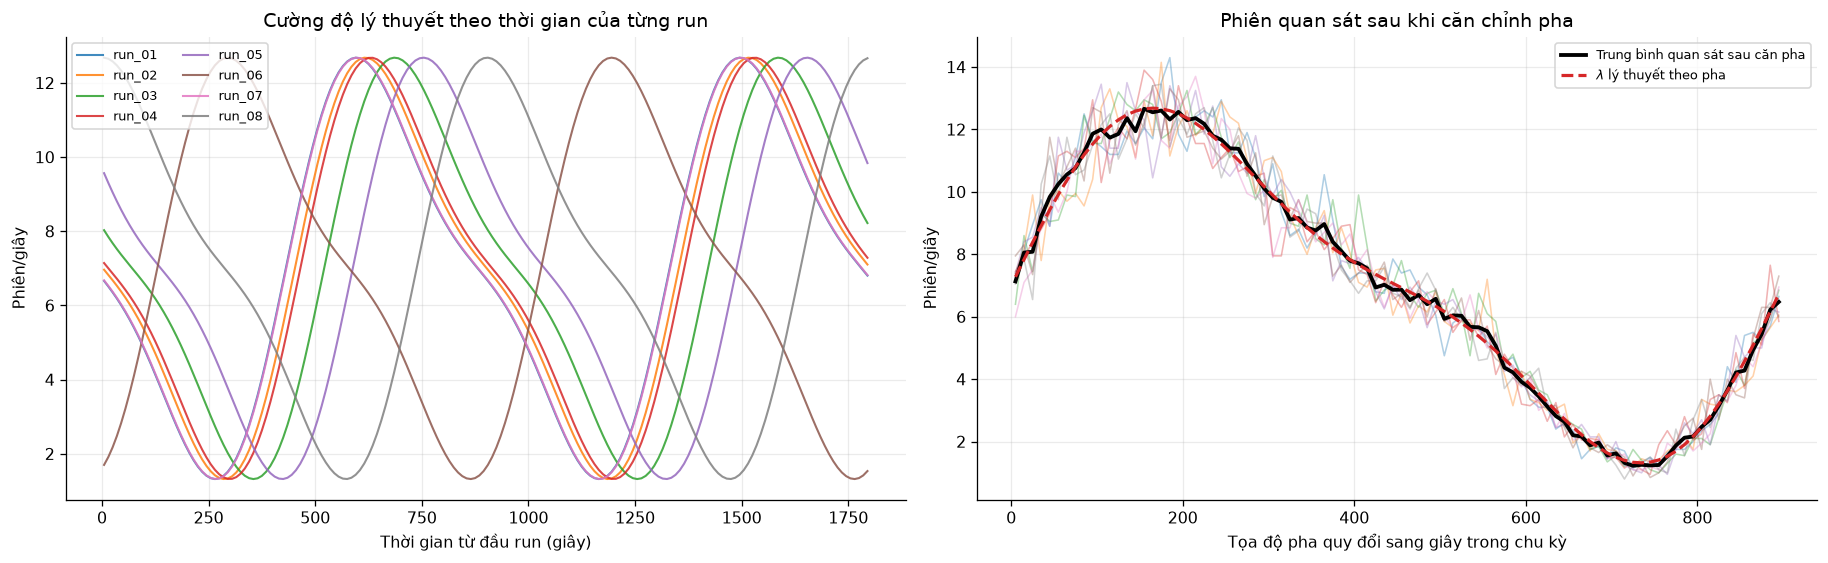

Tương quan giữa trung bình đã căn pha và lambda lý thuyết: 0.9985


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = plt.cm.tab10(np.linspace(0, 1, max(10, len(RUNS))))
phase_grid = np.arange(0, PERIOD, WINDOW_SEC, dtype=float) + WINDOW_SEC / 2
aligned_curves = []

for color, (key_i, run_i) in zip(colors, RUNS.items()):
    x = ANALYSIS[key_i]
    axes[0].plot(
        x["t_mid"], x["lambda_mean"],
        color=color, lw=1.3, alpha=0.85, label=key_i,
    )

    phase_t = np.mod(x["t_mid"].to_numpy() + run_i["phase"] / OMEGA, PERIOD)
    y = x["observed_session_rate"].to_numpy(float)
    phase_bin = np.floor(phase_t / WINDOW_SEC).astype(int)
    by_phase = pd.DataFrame({"bin": phase_bin, "y": y}).groupby("bin")["y"].mean()
    curve = (
        by_phase.reindex(np.arange(len(phase_grid)))
        .interpolate(limit_direction="both")
        .to_numpy()
    )
    aligned_curves.append(curve)
    axes[1].plot(phase_grid, curve, color=color, lw=1, alpha=0.35)

aligned_mean = np.nanmean(np.vstack(aligned_curves), axis=0)
phase_theory = lambda_sessions(phase_grid, 0.0)
axes[1].plot(
    phase_grid, aligned_mean, color="k", lw=2.4,
    label="Trung bình quan sát sau căn pha",
)
axes[1].plot(
    phase_grid, phase_theory, color="C3", lw=2, ls="--",
    label=r"$\lambda$ lý thuyết theo pha",
)

axes[0].set(
    title="Cường độ lý thuyết theo thời gian của từng run",
    xlabel="Thời gian từ đầu run (giây)",
    ylabel="Phiên/giây",
)
axes[0].legend(ncol=2, fontsize=8)
axes[1].set(
    title="Phiên quan sát sau khi căn chỉnh pha",
    xlabel="Tọa độ pha quy đổi sang giây trong chu kỳ",
    ylabel="Phiên/giây",
)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

phase_alignment_corr = np.corrcoef(aligned_mean, phase_theory)[0, 1]
print(
    "Tương quan giữa trung bình đã căn pha và lambda lý thuyết: "
    f"{phase_alignment_corr:.4f}"
)

## 9. Biểu đồ 5 — Timeline phiên người dùng của toàn bộ 8 run NHPP

Đây là **một biểu đồ duy nhất** trên trục thời gian thực nghiệm liên tục:

- đường đỏ: cường độ phiên lý thuyết $\lambda(t)$ của từng run, dùng đúng pha trong **trace_meta.json**;
- đường xanh: số phiên thực tế trong **arrival_trace.csv**, chia cho kích thước cửa sổ;
- nền xen kẽ và nhãn phía trên: ranh giới của từng run;
- khoảng trống trên trục X: thời gian thực tế giữa hai run.

Trục thời gian được đổi từ Unix epoch sang múi giờ **Asia/Ho_Chi_Minh**. Các đoạn được vẽ riêng theo run nên không nối giả qua khoảng nghỉ.

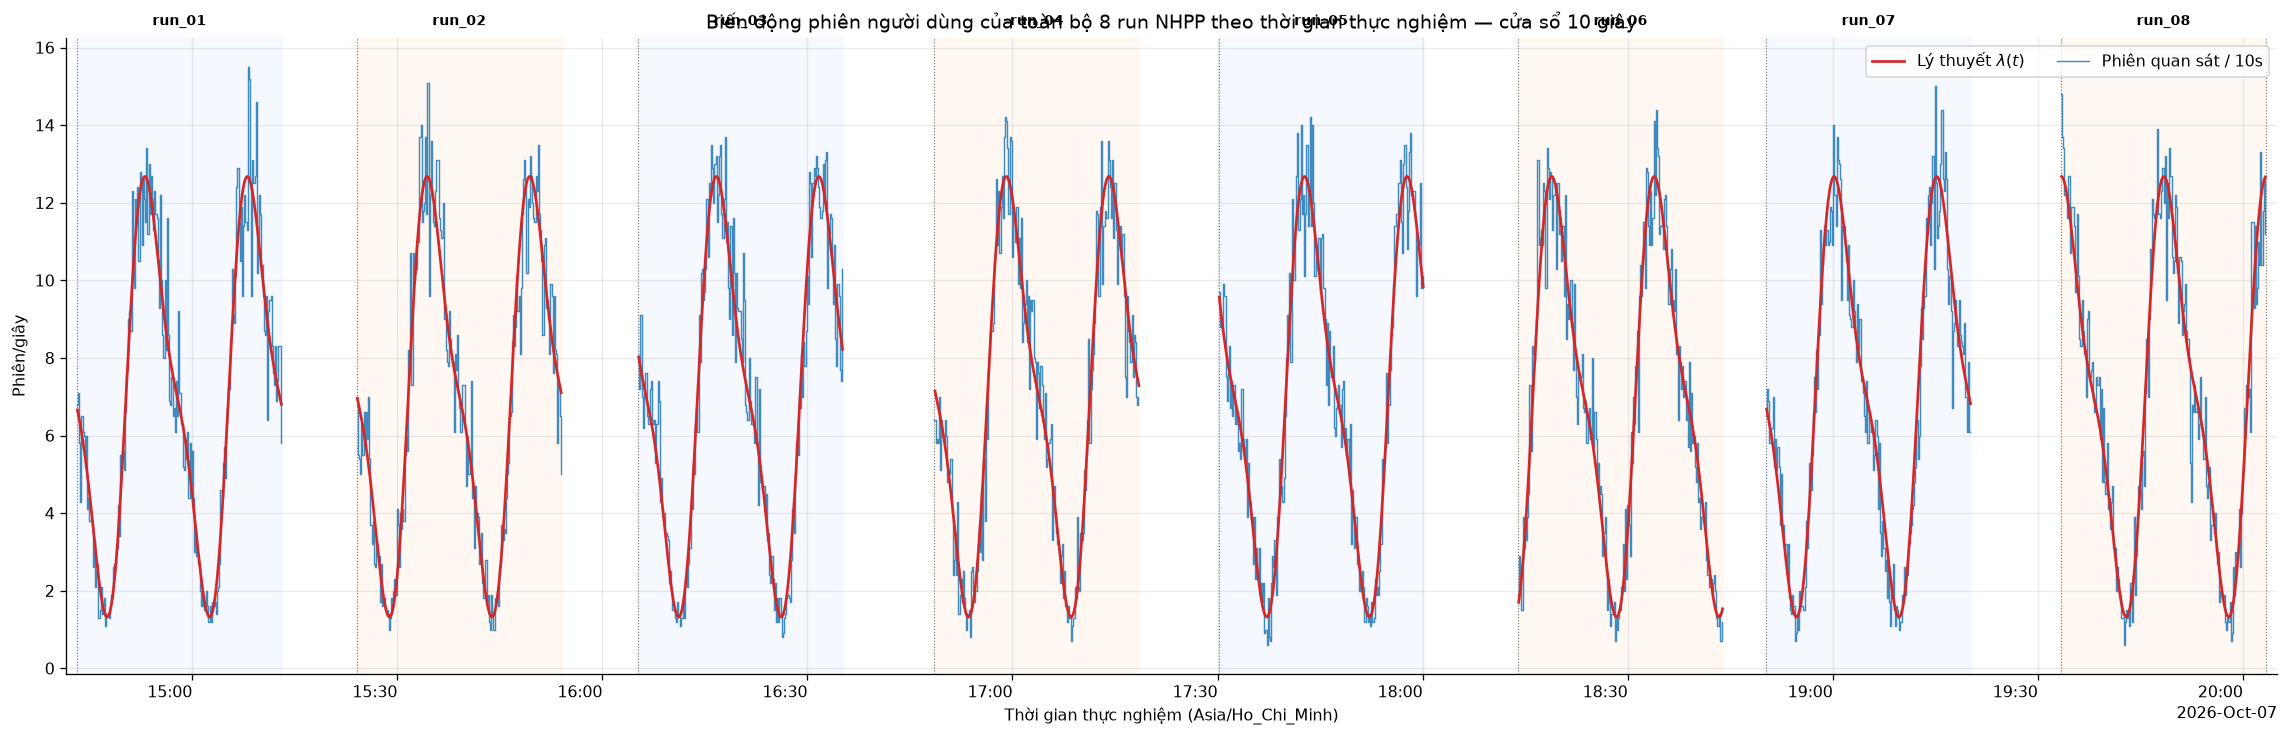

In [34]:
from zoneinfo import ZoneInfo
import matplotlib.dates as mdates

local_tz = ZoneInfo("Asia/Ho_Chi_Minh")
ordered_runs = sorted(
    RUNS.items(),
    key=lambda item: (
        item[1]["driver_epoch"]
        if np.isfinite(item[1]["driver_epoch"])
        else float(item[1]["meta"].get("start", np.inf))
    ),
)

fig, ax = plt.subplots(figsize=(20, 6.5))
shade_colors = ("#eef4ff", "#fff4e8")

for idx, (key_i, run_i) in enumerate(ordered_runs):
    x = ANALYSIS[key_i]
    epoch0 = (
        run_i["driver_epoch"]
        if np.isfinite(run_i["driver_epoch"])
        else float(run_i["meta"]["start"])
    )
    observed_time = pd.to_datetime(
        epoch0 + x["t_start"], unit="s", utc=True
    ).dt.tz_convert(local_tz)
    theory_time = pd.to_datetime(
        epoch0 + x["t_mid"], unit="s", utc=True
    ).dt.tz_convert(local_tz)
    run_start = pd.to_datetime(
        epoch0, unit="s", utc=True
    ).tz_convert(local_tz)
    run_end = pd.to_datetime(
        epoch0 + run_i["duration"], unit="s", utc=True
    ).tz_convert(local_tz)
    run_mid = run_start + (run_end - run_start) / 2

    ax.axvspan(
        run_start, run_end, color=shade_colors[idx % 2],
        alpha=0.55, zorder=0,
    )
    ax.plot(
        theory_time, x["lambda_mean"], color="C3", lw=1.7,
        label=r"Lý thuyết $\lambda(t)$" if idx == 0 else None,
        zorder=3,
    )
    ax.step(
        observed_time, x["observed_session_rate"], where="post",
        color="C0", lw=0.9, alpha=0.85,
        label=f"Phiên quan sát / {WINDOW_SEC}s" if idx == 0 else None,
        zorder=2,
    )
    ax.axvline(run_start, color="0.45", lw=0.7, ls=":", zorder=1)
    ax.text(
        run_mid, 1.015, key_i,
        transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=9, fontweight="bold",
    )

last_key, last_run = ordered_runs[-1]
last_epoch = (
    last_run["driver_epoch"]
    if np.isfinite(last_run["driver_epoch"])
    else float(last_run["meta"]["start"])
)
last_end = pd.to_datetime(
    last_epoch + last_run["duration"], unit="s", utc=True
).tz_convert(local_tz)
ax.axvline(last_end, color="0.45", lw=0.7, ls=":", zorder=1)

locator = mdates.AutoDateLocator(minticks=8, maxticks=18)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(locator, tz=local_tz)
)
ax.set(
    title=(
        f"Biến động phiên người dùng của toàn bộ {len(ordered_runs)} run NHPP "
        f"theo thời gian thực nghiệm — cửa sổ {WINDOW_SEC} giây"
    ),
    xlabel="Thời gian thực nghiệm (Asia/Ho_Chi_Minh)",
    ylabel="Phiên/giây",
)
ax.legend(loc="upper right", ncol=2)
ax.margins(x=0.005)
fig.autofmt_xdate(rotation=0)
plt.tight_layout()
plt.show()

## 10. Kết luận tự động từ dữ liệu

Các ngưỡng sau chỉ để diễn đạt ngắn gọn: tương quan ≥ 0,7 là bám xu hướng rõ; $|z|\le3$ là tổng phiên nằm trong khoảng dao động Poisson thường gặp. Đây không phải kiểm định bác bỏ mô hình từ một run đơn lẻ.

In [35]:
median_corr = stats["session_trend_corr"].median()
max_abs_z = stats["total_session_z"].abs().max()
request_ratio = stats["locust_client_requests"] / stats["designed_expected_requests"]
drop_total = stats["driver_dropped_sessions"].sum(min_count=1)
failure_total = stats["locust_failures"].sum(min_count=1)
coverage = stats["jaeger_to_locust_ratio"].dropna()
planned = pd.Series({
    k: RUNS[k]["driver"].get("planned", np.nan) for k in RUNS
})
completed = stats["driver_completed_sessions"]
unfinished = (planned - completed).clip(lower=0).sum(min_count=1)
phase_span = (
    np.ptp(stats["phase_rad"].to_numpy(float)) if len(stats) > 1 else 0.0
)

trend_text = (
    "Có: số phiên quan sát bám xu hướng lambda(t) rõ"
    if median_corr >= 0.7
    else "Mức bám xu hướng chưa rõ theo ngưỡng tương quan 0,7"
)
total_text = (
    "Có: tất cả tổng phiên đều nằm trong ±3 độ lệch chuẩn Poisson quanh kỳ vọng"
    if max_abs_z <= 3
    else "Có ít nhất một run lệch quá ±3 độ lệch chuẩn Poisson"
)
ratio_min = request_ratio.min()
ratio_max = request_ratio.max()
ratio_mean = request_ratio.mean()
coverage_text = (
    f"Jaeger frontend chỉ ghi nhận trung vị {coverage.median():.1%} so với "
    "Locust; đây là dữ liệu raw/sampling, không phải tổng request."
    if len(coverage)
    else "Không đủ dữ liệu để so sánh Jaeger frontend với Locust."
)

conclusion = f"""
### Nhận xét đã tính từ {len(stats)} run

1. **Lưu lượng phiên có đi theo lambda(t) không?** {trend_text}. Tương quan trung vị theo cửa sổ {WINDOW_SEC}s là **{median_corr:.3f}**.
2. **Tổng số phiên có phù hợp kỳ vọng không?** {total_text}. Giá trị |z| lớn nhất là **{max_abs_z:.3f}**. Không dùng MAE từng cửa sổ để bác bỏ NHPP vì nhiễu Poisson là thành phần của mô hình.
3. **RPS thực tế khác thiết kế thế nào?** Tổng request Locust / tổng request thiết kế nằm trong **{ratio_min:.1%}–{ratio_max:.1%}**, trung bình **{ratio_mean:.1%}**. Locust phản ánh request hoàn tất/được client ghi nhận và có độ trễ do think time cùng thời gian phản hồi; 6 lambda(t) chỉ là đường thiết kế. {coverage_text}
4. **Chu kỳ và tính ngẫu nhiên giữa các run:** pha trải trên khoảng **{phase_span:.3f} rad**; sau căn pha, tương quan đường trung bình quan sát với lý thuyết là **{phase_alignment_corr:.3f}**. Các run có cùng xu hướng chu kỳ nhưng số phiên từng cửa sổ và tổng phiên vẫn dao động ngẫu nhiên.
5. **Yếu tố gây sai lệch quan sát:** think time mũ và request tuần tự trong phiên; thời gian phản hồi làm trễ action; các phiên chưa hoàn tất khi run kết thúc (chênh planned–completed cộng dồn: **{unfinished:.0f}**); arrival bị driver bỏ (**{drop_total:.0f}**); request Locust thất bại (**{failure_total:.0f}**); Jaeger sampling/coverage; và sai số căn mốc giữa thời gian tương đối của trace với Unix timestamp của telemetry.

> Các kết luận trên mô tả đúng bộ dữ liệu đang đọc. Thay đổi RUN_SELECTION, WINDOW_SEC hoặc dữ liệu đầu vào sẽ làm chúng được tính lại tự động.
"""
display(Markdown(conclusion))


### Nhận xét đã tính từ 8 run

1. **Lưu lượng phiên có đi theo lambda(t) không?** Có: số phiên quan sát bám xu hướng lambda(t) rõ. Tương quan trung vị theo cửa sổ 10s là **0.974**.
2. **Tổng số phiên có phù hợp kỳ vọng không?** Có: tất cả tổng phiên đều nằm trong ±3 độ lệch chuẩn Poisson quanh kỳ vọng. Giá trị |z| lớn nhất là **1.969**. Không dùng MAE từng cửa sổ để bác bỏ NHPP vì nhiễu Poisson là thành phần của mô hình.
3. **RPS thực tế khác thiết kế thế nào?** Tổng request Locust / tổng request thiết kế nằm trong **96.7%–100.4%**, trung bình **99.1%**. Locust phản ánh request hoàn tất/được client ghi nhận và có độ trễ do think time cùng thời gian phản hồi; 6 lambda(t) chỉ là đường thiết kế. Jaeger frontend chỉ ghi nhận trung vị 11.4% so với Locust; đây là dữ liệu raw/sampling, không phải tổng request.
4. **Chu kỳ và tính ngẫu nhiên giữa các run:** pha trải trên khoảng **4.246 rad**; sau căn pha, tương quan đường trung bình quan sát với lý thuyết là **0.998**. Các run có cùng xu hướng chu kỳ nhưng số phiên từng cửa sổ và tổng phiên vẫn dao động ngẫu nhiên.
5. **Yếu tố gây sai lệch quan sát:** think time mũ và request tuần tự trong phiên; thời gian phản hồi làm trễ action; các phiên chưa hoàn tất khi run kết thúc (chênh planned–completed cộng dồn: **439**); arrival bị driver bỏ (**0**); request Locust thất bại (**52**); Jaeger sampling/coverage; và sai số căn mốc giữa thời gian tương đối của trace với Unix timestamp của telemetry.

> Các kết luận trên mô tả đúng bộ dữ liệu đang đọc. Thay đổi RUN_SELECTION, WINDOW_SEC hoặc dữ liệu đầu vào sẽ làm chúng được tính lại tự động.
